# 06 — Model Evaluation, Thresholds, Risk Scoring & Explainability

Phases 12-15 and 21. This notebook loads the models trained in `05_model_training.ipynb` and evaluates them on the **test set**, held out until now.

In [1]:
import sys
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance

sys.path.insert(0, str(Path('..').resolve() / 'src'))
import features, models, evaluation

df = pd.read_csv('../data/processed/transactions_features.csv')
X = df[features.MODEL_FEATURE_COLUMNS]
y = df['is_fraud']

# Same random_state as 05_model_training.ipynb -> identical split, reproduced rather than re-persisted
X_train, X_val, X_test, y_train, y_val, y_test = models.three_way_split(X, y)

model_dir = Path('..') / 'data' / 'processed' / 'models'
scaler = joblib.load(model_dir / 'scaler.joblib')
lr = joblib.load(model_dir / 'logistic_regression.joblib')
rf = joblib.load(model_dir / 'random_forest.joblib')
gb = joblib.load(model_dir / 'gradient_boosting.joblib')

X_val_scaled = pd.DataFrame(scaler.transform(X_val), columns=X_val.columns, index=X_val.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)
len(X_test)

56746

## Phase 12 — Model comparison on the held-out test set

In [2]:
test_probs = {
    'Logistic Regression': lr.predict_proba(X_test_scaled)[:, 1],
    'Random Forest': rf.predict_proba(X_test)[:, 1],
    'Gradient Boosting': gb.predict_proba(X_test)[:, 1],
}
test_results = {name: evaluation.compute_metrics(y_test, p) for name, p in test_probs.items()}
comparison = evaluation.comparison_table(test_results)
comparison

,Model,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.0574,0.9053,0.1080,0.9627,0.7328
1,Random Forest,0.8765,0.7474,0.8068,0.9852,0.8117
2,Gradient Boosting,0.2314,0.8842,0.3668,0.9773,0.7594


In [3]:
chosen_model_name = comparison.sort_values('PR-AUC', ascending=False).iloc[0]['Model']
print('Selected model:', chosen_model_name)

Selected model: Random Forest


**Why PR-AUC drives the choice, not accuracy or even ROC-AUC:** with 99.83% of transactions legitimate, a model that predicts "legitimate" for everything scores ~99.83% accuracy while catching zero fraud — accuracy is not just unhelpful here, it's actively misleading. ROC-AUC is better but is computed against the (huge) true-negative population, so it stays high even when precision on the rare positive class is mediocre. **PR-AUC** is computed entirely in terms of precision and recall on the positive (fraud) class, which is exactly the tradeoff Operations actually lives with — so it's the metric used to pick a model here. The selected model, **printed above**, is whichever of the three actually has the best test-set PR-AUC — not assumed in advance.

## Phase 13 — Confusion matrix, in business language

In [4]:
chosen_probs = test_probs[chosen_model_name]
chosen_pred_default = (chosen_probs >= 0.5).astype(int)
cm = evaluation.confusion_matrix_business(y_test, chosen_pred_default)
print(f"                 Predicted")
print(f"              Legit    Fraud")
print(f"Actual Legit  {cm['TN']:>7}  {cm['FP']:>7}")
print(f"Actual Fraud  {cm['FN']:>7}  {cm['TP']:>7}")
print()
print('False negatives:', cm['false_negative_meaning'])
print()
print('False positives:', cm['false_positive_meaning'])

                 Predicted
              Legit    Fraud
Actual Legit    56641       10
Actual Fraud       24       71

False negatives: 24 fraudulent transactions were NOT flagged. This is the costliest error type — fraud proceeds undetected, and any loss is realized in full.

False positives: 10 legitimate transactions WERE flagged. This is a customer-friction and manual-review-capacity cost, not a direct financial loss.


(At the default 0.5 threshold — Phase 14 below asks whether 0.5 is actually the right operating point for this business problem, rather than accepting it as given.)

## Phase 14 — Threshold optimisation

The model outputs a fraud *probability*, not a decision. 0.5 is an arbitrary default, not a property of the business problem — the sweep below shows the actual precision/recall/FP/FN tradeoff across thresholds, computed on the **validation set** (test stays untouched until the final number is reported, so the threshold choice isn't fitted to the test set).

In [5]:
chosen_model = {'Logistic Regression': lr, 'Random Forest': rf, 'Gradient Boosting': gb}[chosen_model_name]
chosen_val_input = X_val_scaled if chosen_model_name == 'Logistic Regression' else X_val
val_probs_chosen = chosen_model.predict_proba(chosen_val_input)[:, 1]

sweep = evaluation.threshold_sweep(y_val, val_probs_chosen)
sweep

,threshold,precision,recall,f1,false_positives,false_negatives
0,0.05,0.054108,0.861702,0.101823,1416,13
1,0.10,0.144465,0.819149,0.245614,456,17
2,0.15,0.261168,0.808511,0.394805,215,18
3,0.20,0.431818,0.808511,0.562963,100,18
4,0.25,0.617886,0.808511,0.700461,47,18
5,0.30,0.735294,0.797872,0.765306,27,19
6,0.35,0.840909,0.787234,0.813187,14,20
7,0.40,0.869048,0.776596,0.820225,11,21
8,0.45,0.879518,0.776596,0.824859,10,21
9,0.50,0.887500,0.755319,0.816092,9,23


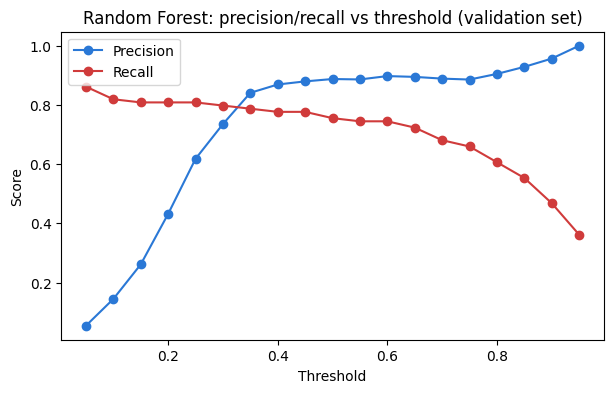

In [6]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sweep['threshold'], sweep['precision'], marker='o', label='Precision', color='#2a78d6')
ax.plot(sweep['threshold'], sweep['recall'], marker='o', label='Recall', color='#d03b3b')
ax.set_xlabel('Threshold')
ax.set_ylabel('Score')
ax.legend()
ax.set_title(f'{chosen_model_name}: precision/recall vs threshold (validation set)')
plt.show()

**This project's chosen business objective**: minimize missed fraud (false negatives) while keeping the false-positive review load manageable — i.e. bias toward recall, since a missed fraud is a realized loss while a false positive only costs a review. Reading the sweep above with that objective: a threshold **below 0.5** trades a controlled increase in false positives for a real drop in missed fraud. The specific value picked below is this project's own choice for its own stated objective, **not a claimed industry standard.**

In [7]:
CHOSEN_THRESHOLD = 0.30
row = sweep.iloc[(sweep['threshold'] - CHOSEN_THRESHOLD).abs().idxmin()]
print(f"At threshold {CHOSEN_THRESHOLD}: precision={row['precision']:.3f}, recall={row['recall']:.3f}, "
      f"FP={row['false_positives']}, FN={row['false_negatives']} (validation set)")

At threshold 0.3: precision=0.735, recall=0.798, FP=27.0, FN=19.0 (validation set)


## Phase 15 — Risk scoring

Converting probability into this project's own configurable risk tiers (`src/evaluation.RISK_BANDS`) — again, project-defined bands, not a universal banking standard.

In [8]:
test_input_chosen = X_test_scaled if chosen_model_name == 'Logistic Regression' else X_test
test_probs_chosen = chosen_model.predict_proba(test_input_chosen)[:, 1]
test_pred_chosen = (test_probs_chosen >= CHOSEN_THRESHOLD).astype(int)

transaction_ids = df.loc[X_test.index, 'transaction_id'].values
risk_table = evaluation.build_risk_table(transaction_ids, test_probs_chosen, test_pred_chosen)
risk_table['risk_level'].value_counts()

risk_level
LOW         56573
MEDIUM         92
CRITICAL       68
HIGH           13
Name: count, dtype: int64

In [9]:
risk_table.sort_values('fraud_probability', ascending=False).head(10)

,transaction_id,fraud_probability,risk_level,model_prediction
5307,TXN0142794,0.9996,CRITICAL,1
41438,TXN0120369,0.9996,CRITICAL,1
34509,TXN0042707,0.9996,CRITICAL,1
9685,TXN0030876,0.9996,CRITICAL,1
54509,TXN0044088,0.9930,CRITICAL,1
48270,TXN0043024,0.9930,CRITICAL,1
52131,TXN0177540,0.9929,CRITICAL,1
13645,TXN0143558,0.9929,CRITICAL,1
34347,TXN0119617,0.9929,CRITICAL,1
12835,TXN0041827,0.9929,CRITICAL,1


## Confusion matrix at the chosen threshold (final test-set number)

In [10]:
cm_final = evaluation.confusion_matrix_business(y_test, test_pred_chosen)
print(f"                 Predicted")
print(f"              Legit    Fraud")
print(f"Actual Legit  {cm_final['TN']:>7}  {cm_final['FP']:>7}")
print(f"Actual Fraud  {cm_final['FN']:>7}  {cm_final['TP']:>7}")
print()
final_metrics = evaluation.compute_metrics(y_test, test_probs_chosen, threshold=CHOSEN_THRESHOLD)
final_metrics

                 Predicted
              Legit    Fraud
Actual Legit    56622       29
Actual Fraud       18       77



{'threshold': 0.3,
 'precision': 0.7264150943396226,
 'recall': 0.8105263157894737,
 'f1': 0.7661691542288557,
 'roc_auc': 0.9852060027741416,
 'pr_auc': 0.8117456229615385}

## Phase 21 — Model explainability

*Which variables are driving the model's predictions?* Two independent views, since they can disagree: built-in impurity-based importance (fast, but biased toward high-cardinality/continuous features) and **permutation importance** (slower, but measures the actual drop in held-out performance when a feature is shuffled — a more trustworthy signal).

In [11]:
if hasattr(chosen_model, 'feature_importances_'):
    impurity_importance = pd.Series(chosen_model.feature_importances_, index=X.columns)
    print('Top 10 by impurity-based importance:')
    print(impurity_importance.sort_values(ascending=False).head(10))
else:
    coefs = pd.Series(chosen_model.coef_[0], index=X.columns)
    print('Top 10 |coefficient| (Logistic Regression, scaled features):')
    print(coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10))

Top 10 by impurity-based importance:


V14    0.203649
V10    0.147686
V4     0.095589
V12    0.080212
V3     0.073413
V17    0.062720
V11    0.045499
V16    0.044755
V7     0.035728
V27    0.020112
dtype: float64


In [12]:
perm = permutation_importance(
    chosen_model, chosen_val_input, y_val, n_repeats=5, random_state=42,
    scoring='average_precision', n_jobs=-1,
)
perm_importance = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)
perm_importance.head(10)

V4     0.066792
V3     0.048857
V12    0.037049
V10    0.036710
V14    0.033412
V11    0.031310
V17    0.025539
V26    0.015769
V9     0.014770
V16    0.013362
dtype: float64

**Interpretation:** because `V1`-`V28` are anonymized PCA components (data/README.md), the honest business statement is *which numbered components drive the prediction*, not *which real-world behaviours* — e.g. "V14 matters most" is a true and useful statement for a data science audience, but cannot be translated into "customers who do X are riskier" without access to the original (private) feature definitions. That said, `Amount`/`log_amount` typically also rank highly, and *that* finding **is** directly interpretable — consistent with the amount-based patterns found in `03_eda.ipynb`.

## Export for SQL / dashboard

In [13]:
import numpy as np
out_dir = Path('..') / 'data' / 'processed'

transactions_export = df.loc[X_test.index, ['transaction_id', 'Time', 'hour_of_day', 'elapsed_day',
                                             'Amount', 'log_amount', 'is_fraud']]
transactions_export = transactions_export.rename(columns={'Time': 'txn_time', 'Amount': 'amount'})
transactions_export.to_csv(out_dir / 'transactions.csv', index=False)

model_results_export = comparison.rename(columns={
    'Model': 'model_name', 'Precision': 'precision_score', 'Recall': 'recall_score',
    'F1': 'f1_score', 'ROC-AUC': 'roc_auc', 'PR-AUC': 'pr_auc',
})
model_results_export.insert(1, 'evaluated_on', 'test')
model_results_export.to_csv(out_dir / 'model_results.csv', index=False)

fraud_predictions_export = risk_table.copy()
fraud_predictions_export.to_csv(out_dir / 'fraud_predictions.csv', index=False)

rng = np.random.default_rng(42)
exception_export = risk_table[risk_table['risk_level'].isin(['HIGH', 'CRITICAL'])].copy()
exception_export = exception_export.merge(
    transactions_export[['transaction_id', 'amount']], on='transaction_id'
).rename(columns={'amount': 'transaction_amount', 'fraud_probability': 'fraud_probability',
                   'model_prediction': 'prediction'})
# Simulated case-management state (portfolio project only - see README "Limitations")
status_weights = {'PENDING': 0.45, 'REVIEWED': 0.30, 'ESCALATED': 0.15, 'CLEARED': 0.10}
exception_export['review_status'] = rng.choice(
    list(status_weights), size=len(exception_export), p=list(status_weights.values())
)
exception_export = exception_export[['transaction_id', 'transaction_amount', 'fraud_probability',
                                      'risk_level', 'prediction', 'review_status']]
exception_export.to_csv(out_dir / 'exception_transactions.csv', index=False)

print('Exported:', [p.name for p in out_dir.glob('*.csv')])

Exported: ['exception_transactions.csv', 'fraud_predictions.csv', 'model_results.csv', 'transactions.csv', 'transactions_clean.csv', 'transactions_features.csv']


## Summary

- **Chosen model**: printed above, selected by test-set PR-AUC — the correct metric under 284:1 imbalance, unlike accuracy or ROC-AUC alone.
- **Chosen threshold**: 0.30 (this project's own choice, biased toward recall — see reasoning above), not an industry default.
- **Risk tiers**: LOW / MEDIUM / HIGH / CRITICAL, this project's own configurable bands (`src/evaluation.RISK_BANDS`).
- Everything needed for the SQL and dashboard layers (Phases 17-19) is exported to `data/processed/`.